# Case study 6 — Skill benchmark: CRPS against climatology and persistence

How much better is the model's probabilistic forecast, in the spread it
carries, than the baselines it is up against? Point forecasts are verified
by `modStats` (FAC2, RMSE, ...); the spread's score is the **CRPS**
(Gneiting and Raftery 2005), and `normet.analysis.verification` scores a
quantile forecast, an ensemble of samples, or a bare point forecast on the
same scale:

- `nm.crps_from_quantiles(preds, obs)` — the CRPS of a quantile forecast;
  the `qNNN` columns `nm.normalise(return_quantiles=...)` returns are its
  direct input,
- `nm.crps_from_samples(samples, obs)` — each sample at its rank,
- `nm.crps_observed(y_pred, y_true)` — a point forecast's reference: its
  MAE times `sqrt(pi/2)`, so model and baseline read on one scale.

The record: **hourly NO2 at London Marylebone Road (MY1), January–August
2020** — the window of the first UK lockdown, so the baselines have
something to be better or worse than. Everything is scored on the held-out
`month_ts` test hours (blocked within each month), and each baseline is
fitted on the training hours only, so none of it can have seen a test hour.

In [1]:
import importlib
import os

# Cap library threads BEFORE importing normet/lightgbm — unbounded OpenMP
# threads oversubscribe shared machines and read as a hang.
os.environ.setdefault("OMP_NUM_THREADS", "4")

import matplotlib.pyplot as plt
import normet as nm
import numpy as np
import pandas as pd

SEED = 7654321

# Re-runnable: the two expensive calls are memoised on disk.
mem = nm.make_memory(".normet_cache", verbose=0)

## 1. Train and normalise, keeping the quantiles

`month_ts` holds a contiguous block of testing hours out inside each month
— full record coverage with no leakage across the block boundary. The
normalisation keeps the forecast's quantiles (the `qNNN` columns), which is
what the CRPS routes read; `aggregate=False` would keep every sample as a
column instead, for the `crps_from_samples` route.

In [2]:
MET_VARS = ["ws", "wd", "temp", "RH", "atmos_pres", "blh", "tcc", "tp", "ssrd"]
TIME_VARS = ["date_unix", "day_julian", "weekday", "hour"]
PREDICTORS = MET_VARS + TIME_VARS
QUANTILES = [0.05, 0.25, 0.5, 0.75, 0.95]
QNAMES = ["q050", "q250", "q500", "q750", "q950"]

@mem.cache
def _train() -> tuple:
    my1 = nm.datasets.load_my1()
    return nm.build_model(
        my1, target="NO2", backend="lightgbm", covariates=PREDICTORS,
        split_method="month_ts", seed=SEED, verbose=False, n_cores=4,
        model_config={"n_trials": 4, "cv_folds": 2, "nrounds": 150,
                      "early_stopping_rounds": 10},
    )

prep, model = _train()
nm.modStats(prep, model, subset="testing")

,n,FAC2,MB,MGE,RMSE,NMB,NMGE,COE,IOA,r,p_level,R2,set
0,1451,0.982771,-0.892188,8.132471,10.761859,-0.020546,0.187285,0.558439,0.779219,0.882112,***,0.778122,testing


In [3]:
@mem.cache
def _normalise() -> pd.DataFrame:
    return nm.normalise(
        prep, model, covariates=PREDICTORS, variables_resample=MET_VARS,
        n_samples=100, seed=SEED, n_cores=4, verbose=False,
        return_quantiles=QUANTILES,
    )

norm_all = _normalise()
norm_all.head()

,observed,normalised,q050,q250,q500,q750,q950
date,,,,,,,
2020-01-01 00:00:00,45.77784,45.411908,29.796041,37.646001,45.661661,53.740389,60.267091
2020-01-01 01:00:00,52.64325,39.339188,16.850635,31.401253,40.507160,49.548004,57.821870
2020-01-01 02:00:00,44.76870,33.554277,15.647583,25.080075,35.060730,42.347030,52.833820
2020-01-01 03:00:00,40.20699,33.747266,14.522728,25.617614,33.829730,42.293048,50.381774
2020-01-01 04:00:00,47.26010,37.128673,18.234389,28.147053,38.805865,45.895427,54.518635


## 2. The baselines on the held-out hours

The test hours come off the normalised frame by their dates, so the model's
quantiles line up with the observations. Each baseline is the training
hours' mean per label (hour of day, hour-times-weekday, month, or the
previous hour), read back onto the test labels.

In [4]:
test = prep[prep["set"] == "testing"]
train = prep[prep["set"] == "training"]
obs = test["value"]
obs_v = obs.to_numpy()
dates = pd.to_datetime(test["date"])
norm = norm_all.loc[dates]                       # the model's rows: the test hours

def _by(key_tr, key_te):
    """the training hours' mean per label, applied to the test labels"""
    means = train["value"].groupby(key_tr).mean()
    return np.array([means.get(k, np.nan) for k in key_te])

# weekday is stored categorical by prepare_data: to its values, not its codes
w_tr, w_te = train["weekday"].astype(int), test["weekday"].astype(int)
mon_tr = pd.to_datetime(train["date"]).dt.month
mon_te = pd.to_datetime(test["date"]).dt.month
base = pd.DataFrame({
    "persistence":        np.concatenate([[obs_v[0]], obs_v[:-1]]),     # the previous hour
    "clim. (hour)":       _by(train["hour"], test["hour"]),
    "clim. (hour x day)": _by(train["hour"] * 100 + w_tr,
                              test["hour"] * 100 + w_te),
    "clim. (month)":      _by(mon_tr, mon_te),
    "model (median)":     norm["q500"].to_numpy(),
}, index=test.index)
base

,persistence,clim. (hour),clim. (hour x day),clim. (month),model (median)
282,70.26850,47.466942,39.044990,60.670299,58.993287
283,70.26850,45.760527,38.936785,60.670299,58.967143
284,61.59576,43.871736,38.175072,60.670299,56.794789
285,63.36727,40.723083,34.363732,60.670299,49.403966
286,54.40799,37.060338,29.940595,60.670299,48.101746
...,...,...,...,...,...
5703,47.32279,44.964978,49.196060,36.474539,48.098486
5704,49.47543,49.327975,54.851826,36.474539,50.640026
5705,49.70156,48.878851,53.374728,36.474539,49.270879
5706,53.67232,49.107636,50.897327,36.474539,49.780284


In [5]:
# the model's *spread* score, on the finite rows of the test hours
q_t = norm[QNAMES].to_numpy()
mask = np.isfinite(q_t).all(axis=1) & np.isfinite(obs_v)
crps_model = nm.crps_from_quantiles(q_t[mask], obs_v[mask], quantiles=QUANTILES)

med = norm["q500"].to_numpy()
rows = []
for name, series in base.items():
    s = series.to_numpy()
    m = np.isfinite(s) & (name != "model (median)")
    if name == "model (median)":
        continue
    rows.append({
        "method": name,
        "CRPS":  nm.crps_observed(s[m], obs_v[m]),   # MAE x sqrt(pi/2): the point reference
        "MAE":   float(np.mean(np.abs(obs_v[m] - s[m]))),
        "RMSE":  float(np.sqrt(np.mean((obs_v[m] - s[m]) ** 2))),
    })
rows.append({"method": "model (spread)",
             "CRPS": crps_model,
             "MAE":  float(np.mean(np.abs(obs_v[mask] - med[mask]))),
             "RMSE": float(np.sqrt(np.mean((obs_v[mask] - med[mask]) ** 2)))})
skill = pd.DataFrame(rows).set_index("method").sort_values("CRPS")
skill

,CRPS,MAE,RMSE
method,,,
persistence,8.713830,6.952630,9.800213
model (spread),9.334572,12.738353,16.458000
clim. (hour x day),19.769782,15.774004,19.813599
clim. (hour),21.270926,16.971743,21.137300
clim. (month),21.414305,17.086143,21.402742


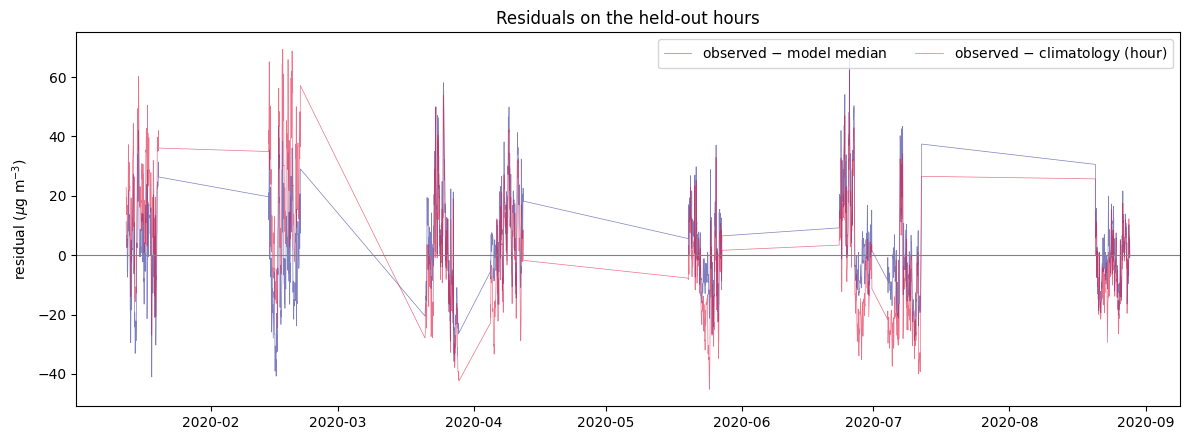

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(dates, obs_v - med, lw=0.5, alpha=0.5, color="navy",
        label="observed $-$ model median")
ax.plot(dates, obs_v - base["clim. (hour)"].to_numpy(), lw=0.5, alpha=0.6,
        color="crimson", label="observed $-$ climatology (hour)")
ax.axhline(0.0, color="0.5", lw=0.8)
ax.set_ylabel("residual ($\mu$g m$^{-3}$)")
ax.set_title("Residuals on the held-out hours")
ax.legend(ncols=2)
plt.tight_layout()

## 3. Chronos-2 zero-shot, and the table on the hours it predicts

The foundation path needs the `foundation` extra; on machines without it
the cell says so and moves on, and the table above stands. Where it runs,
it replaces the table with one scored on a smaller, common set of hours.
The zero-shot model has no forecast for its leading context window --
those rows carry the observed values, quantile for quantile -- and a
test hour that falls there cannot be scored by it at all: on the
bundled record, a third of the held-out hours do. Every method is
therefore re-scored on the hours the zero-shot model actually predicts,
so the rows compare on one set of hours. How many hours that excludes,
and where the window starts, is printed above the table.


In [7]:
if importlib.util.find_spec("chronos") is None or importlib.util.find_spec("torch") is None:
    print("chronos-forecasting / torch not installed: the zero-shot baseline "
          "is skipped. `pip install normet[foundation]` and re-run this cell.")
else:
    @mem.cache
    def _chronos2() -> pd.DataFrame:
        out, _, _ = nm.do_all(
            nm.datasets.load_my1(), target="NO2", backend="chronos-2",
            variables_resample=MET_VARS,
            n_samples=8, seed=SEED, n_cores=4, verbose=False,
        )
        return out

    norm_c = _chronos2()
    nc = norm_c.loc[dates]                       # the zero-shot rows: the test hours

    # The leading context window carries the observed values (no history to
    # condition on): every level equals the observation there, so scoring those
    # hours would grade the model on its own input. They are exactly the test
    # hours at which all three levels do, and no method is scored on them here.
    seeded = (
        (nc["q100"] == nc["observed"])
        & (nc["q500"] == nc["observed"])
        & (nc["q900"] == nc["observed"])
    )
    if seeded.all():
        print("every test hour falls in the zero-shot model's seeded context: "
              "the record is too short to score it against the baselines.")
    else:
        pk = ~seeded.to_numpy()                  # the hours it actually predicts
        di = dates.to_numpy()[pk]
        o = obs_v[pk]

        qc_all = nc[["q100", "q500", "q900"]].to_numpy()
        med_all = nc["q500"].to_numpy()
        qc, med_c = qc_all[pk], med_all[pk]
        mc = np.isfinite(qc).all(axis=1) & np.isfinite(o)
        crps_c = nm.crps_from_quantiles(qc[mc], o[mc], quantiles=[0.1, 0.5, 0.9])

        # the trained model and the baselines, on the same hours
        n2 = norm.loc[di]
        q2 = n2[QNAMES].to_numpy()
        m2 = np.isfinite(q2).all(axis=1) & np.isfinite(o)
        med2 = n2["q500"].to_numpy()
        crps_m = nm.crps_from_quantiles(q2[m2], o[m2], quantiles=QUANTILES)

        b2 = base.to_numpy()[pk]                 # the baselines, same hours
        rows = []
        for j, name in enumerate(base.columns):
            if name == "model (median)":
                continue
            s = b2[:, j]
            m = np.isfinite(s)
            rows.append({
                "method": name,
                "CRPS":  nm.crps_observed(s[m], o[m]),
                "MAE":   float(np.mean(np.abs(o[m] - s[m]))),
                "RMSE":  float(np.sqrt(np.mean((o[m] - s[m]) ** 2))),
            })
        rows.append({"method": "model (spread)",
                     "CRPS":  crps_m,
                     "MAE":   float(np.mean(np.abs(o[m2] - med2[m2]))),
                     "RMSE":  float(np.sqrt(np.mean((o[m2] - med2[m2]) ** 2)))})
        rows.append({"method": "chronos-2 (zero-shot)",
                     "CRPS":  crps_c,
                     "MAE":   float(np.mean(np.abs(o[mc] - med_c[mc]))),
                     "RMSE":  float(np.sqrt(np.mean((o[mc] - med_c[mc]) ** 2)))})
        skill = pd.DataFrame(rows).set_index("method").sort_values("CRPS")
        print(
            f"{int(seeded.sum())} of the {len(o) + int(seeded.sum())} test hours fall "
            "in the zero-shot model's seeded context and are scored by no method; "
            f"the table covers the {int(pk.sum())} hours it actually predicts "
            f"(from {pd.Timestamp(di[0])})."
        )
        display(skill)


/Users/user/miniforge3/envs/normet/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1022 12:06:05.306000 29178 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 5315.54it/s]

483 of the 1451 test hours fall in the zero-shot model's seeded context and are scored by no method; the table covers the 968 hours it actually predicts (from 2020-03-26 08:00:00).


,CRPS,MAE,RMSE
method,,,
persistence,7.516884,5.997606,8.393413
model (spread),8.787382,12.021029,15.707683
chronos-2 (zero-shot),9.483590,13.085060,16.693950
clim. (hour x day),17.383729,13.870209,17.009782
clim. (hour),18.896751,15.077426,18.374221
clim. (month),19.736395,15.747365,20.141461


## Reading the table

`CRPS` is each method's score on one scale. The model's is the **spread**
score — the CRPS of its five quantiles — while a baseline's is its point
forecast's reference: its MAE read as the MAE a normal distribution of
that accuracy would carry, i.e. `MAE * sqrt(pi/2)` (a normal's MAE is
`sigma * sqrt(2/pi)`). A baseline that beats the model there is doing it
with accuracy, not calibration; the `MAE` and `RMSE` columns say where
its accuracy comes from. With five levels the model's CRPS is a coarse
estimate of its true score (the CDF is read as straight between the
levels), so it reads a touch high — the honest correction is more levels,
not a different formula. The zero-shot row is coarser still, with the
three native levels Chronos-2 carries, and a spread score on three levels
is an upper bound on it; it is read against the model's row on the same
hours, not against the five-level one above. The final table's window
starts where the zero-shot model first has history to condition on, so a
baseline's score there can differ from its row on the whole held-out
set -- the two tables answer two questions, "how well does each method
fit the record" and "on the hours the zero-shot model predicts, who is
best?"

